# Analytics, Baseline Modelling and Well-being Score
**Project:** Personalized Digital Lifestyle and Well-being Intelligence System (Group 9)

This notebook is the **Modelling** stage of the pipeline (Python, Pandas, NumPy, Scikit-learn) and follows the project abstract:

| Abstract requirement | Where it is done |
|---|---|
| Build an individual behavioural baseline over time | Section 3 |
| Exploratory analysis and correlations among lifestyle factors | Section 2 |
| Personalised well-being score relative to the user's own baseline | Section 4 |
| Model that detects and flags deviations from normal behaviour | Section 5 |
| Explainable, personalised recommendations | Section 6 |
| Trends, flagged deviations and score for the Streamlit dashboard | Sections 7 and 9 |
| Which factors are linked to changes in well-being | Section 8 |

**Data note:** the dataset is synthetic. It has sleep, screen time, activity and notifications but **no stress or mood columns**, so the score uses the factors available. If `stress` or `mood` columns are added later, Section 3 picks them up automatically.

## 1. Load and check the data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import IsolationForest

# Find the repo root and the cleaned file, wherever the notebook is run from
here = Path.cwd()
candidates = [here, here.parent, here.parent.parent]
ROOT = next((p for p in candidates if (p / "notebooks" / "digital_wellbeing_cleaned.csv").exists()), None)
DATA = ROOT / "notebooks" / "digital_wellbeing_cleaned.csv" if ROOT else Path("digital_wellbeing_cleaned.csv")
RESULTS = (ROOT or here) / "results"
RESULTS.mkdir(exist_ok=True)
print("Reading:", DATA, "| exists:", DATA.exists())

df = pd.read_csv(DATA, parse_dates=["date"])
df = df.drop(columns=["wellbeing_score"], errors="ignore")      # drop the old placeholder score
df = df.drop_duplicates().sort_values(["user_id", "date"]).reset_index(drop=True)

print("Rows:", len(df), "| Users:", df.user_id.nunique(), "| Days per user:", df.groupby("user_id").size().unique())
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Reading: /home/claude/proj/notebooks/digital_wellbeing_cleaned.csv | exists: True


Rows: 261390 | Users: 8713 | Days per user: [30]
Missing values: 0


,record_id,user_id,date,day_index,day_of_week,is_weekend,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,physical_activity_minutes
0,R0000001,U00001,2026-09-01,1,Tuesday,0,2.35,0.63,0.23,1.18,6.90,261.0,151.0,70.0
1,R0000002,U00001,2026-09-02,2,Wednesday,0,2.86,0.67,0.31,1.28,7.66,250.0,145.0,65.0
2,R0000003,U00001,2026-09-03,3,Thursday,0,2.91,0.69,0.32,1.75,7.67,206.0,142.0,62.0
3,R0000004,U00001,2026-09-04,4,Friday,0,2.45,0.66,0.26,1.22,8.18,132.0,123.0,103.0
4,R0000005,U00001,2026-09-05,5,Saturday,1,3.32,0.96,0.48,0.75,7.54,203.0,120.0,99.0


## 2. Exploratory analysis and correlations

,count,mean,std,min,25%,50%,75%,max
daily_screen_time_hours,261390.0,7.99,2.98,0.66,5.59,7.84,10.22,16.00
social_media_hours,261390.0,2.52,1.47,0.11,1.38,2.25,3.41,13.74
gaming_hours,261390.0,1.74,1.27,0.00,0.78,1.49,2.44,10.05
work_study_hours,261390.0,2.09,1.29,0.08,1.10,1.83,2.83,9.75
sleep_hours,261390.0,6.83,1.47,3.00,5.69,6.82,7.96,10.50
notifications_per_day,261390.0,134.86,71.62,8.00,75.00,131.00,188.00,400.00
app_opens_per_day,261390.0,97.43,51.03,7.00,54.00,95.00,137.00,300.00
physical_activity_minutes,261390.0,43.04,20.52,0.00,28.00,41.00,55.00,180.00


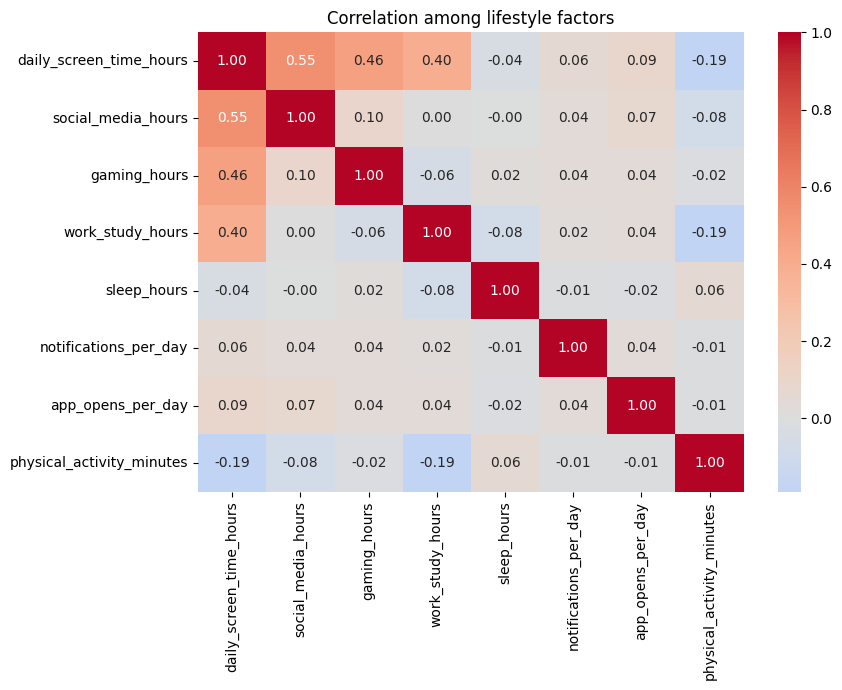

Strongest correlations:


daily_screen_time_hours  social_media_hours           0.546
                         gaming_hours                 0.462
                         work_study_hours             0.396
work_study_hours         physical_activity_minutes   -0.190
daily_screen_time_hours  physical_activity_minutes   -0.189
social_media_hours       gaming_hours                 0.099
dtype: float64

In [2]:
FACTORS = ["daily_screen_time_hours", "social_media_hours", "gaming_hours", "work_study_hours",
           "sleep_hours", "notifications_per_day", "app_opens_per_day", "physical_activity_minutes"]
display(df[FACTORS].describe().T.round(2))

corr = df[FACTORS].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among lifestyle factors")
plt.tight_layout(); plt.savefig(RESULTS / "correlation_heatmap.png", dpi=120); plt.show()

# Strongest pairs (ignoring the diagonal)
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print("Strongest correlations:"); display(pairs.head(6).round(3))

**Reading the result:** note which pairs are strongly related and which are close to zero. Weak relationships between most factors are a finding in themselves and should be reported as such, not hidden.

## 3. Individual behavioural baseline
Each user's baseline for a factor is the **mean and standard deviation of that same user's previous 7 days** (shifted by one day, so today is never compared with itself). A baseline needs at least 5 earlier days, so each user's first days have no score (*building baseline*).

In [3]:
# direction: -1 = higher is worse for well-being, +1 = higher is better
DIRECTION = {"daily_screen_time_hours": -1, "sleep_hours": +1,
             "physical_activity_minutes": +1, "notifications_per_day": -1}
WEIGHT    = {"daily_screen_time_hours": .35, "sleep_hours": .35,
             "physical_activity_minutes": .15, "notifications_per_day": .15}

# Optional factors from the abstract, used only if the columns exist
for col, d, w in [("stress", -1, .20), ("mood", +1, .20)]:
    if col in df.columns:
        DIRECTION[col] = d; WEIGHT[col] = w
total = sum(WEIGHT.values()); WEIGHT = {k: v / total for k, v in WEIGHT.items()}   # weights sum to 1
print("Score factors and weights:", {k: round(v, 2) for k, v in WEIGHT.items()})

WINDOW, MIN_DAYS = 7, 5
g = df.groupby("user_id")
for c in DIRECTION:
    base_mean = g[c].transform(lambda s: s.shift(1).rolling(WINDOW, min_periods=MIN_DAYS).mean())
    base_std  = g[c].transform(lambda s: s.shift(1).rolling(WINDOW, min_periods=MIN_DAYS).std())
    base_std  = base_std.clip(lower=df[c].std() * 0.1)          # avoid dividing by a near-zero spread
    df[c + "_base"] = base_mean
    df[c + "_z"]    = ((df[c] - base_mean) / base_std).clip(-3, 3)   # distance from own normal

df["has_baseline"] = df[[c + "_z" for c in DIRECTION]].notna().all(axis=1)
print("Rows with a baseline:", int(df.has_baseline.sum()), "of", len(df))

Score factors and weights: {'daily_screen_time_hours': 0.35, 'sleep_hours': 0.35, 'physical_activity_minutes': 0.15, 'notifications_per_day': 0.15}


Rows with a baseline: 217825 of 261390


## 4. Personalised well-being score
`deviation` = weighted sum of each factor's z-score, signed so that **positive means better than the user's own normal**.
`wellbeing_score = 70 + 10 x deviation`, limited to 0 to 100. A score of 70 means "typical for this user"; above 70 is better than usual, below 70 is worse than usual.

count    217825.0
mean         69.9
std           7.7
min          40.1
25%          64.8
50%          69.9
75%          75.0
max         100.0
Name: wellbeing_score, dtype: float64


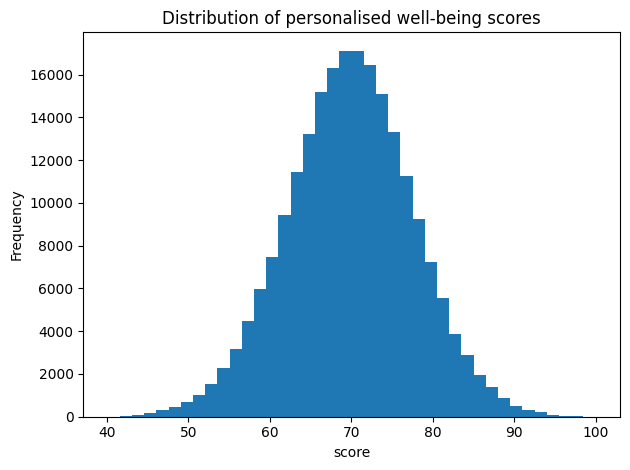

In [4]:
for c in DIRECTION:
    df[c + "_contrib"] = WEIGHT[c] * DIRECTION[c] * df[c + "_z"]        # how much each factor moved the score

df["deviation"] = df[[c + "_contrib" for c in DIRECTION]].sum(axis=1, min_count=len(DIRECTION))
df["wellbeing_score"] = (70 + 10 * df["deviation"]).clip(0, 100).round(1)

print(df["wellbeing_score"].describe().round(1))
df["wellbeing_score"].plot(kind="hist", bins=40, title="Distribution of personalised well-being scores")
plt.xlabel("score"); plt.tight_layout(); plt.savefig(RESULTS / "score_distribution.png", dpi=120); plt.show()

## 5. Deviation detection
Two methods are used:
1. **Rule (sustained deviation):** the day is flagged when behaviour has been clearly worse than the user's own normal (`deviation < -1`) for **3 or more days in a row**. This matches the abstract's idea of unhealthy trends caught early.
2. **Model (Isolation Forest):** an unsupervised model on the per-factor z-scores that finds unusual days, even when no single factor is extreme.

In [5]:
# 1) Sustained-deviation rule
bad = (df["deviation"] < -1).astype(int)
df["bad_streak"] = bad.groupby(df["user_id"]).transform(lambda s: s.groupby((s == 0).cumsum()).cumsum())
df["flagged"] = (df["bad_streak"] >= 3).astype(int)

# 2) Isolation Forest on days that have a baseline
zcols = [c + "_z" for c in DIRECTION]
mask = df["has_baseline"]
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42, n_jobs=-1)
iso.fit(df.loc[mask, zcols])
df["anomaly"] = 0
df.loc[mask, "anomaly"] = (iso.predict(df.loc[mask, zcols]) == -1).astype(int)

print("Sustained-deviation flags:", int(df.flagged.sum()), f"({df.flagged.mean()*100:.2f}% of days)")
print("Isolation Forest anomalies:", int(df.anomaly.sum()), f"({df.anomaly.mean()*100:.2f}% of days)")
print("Flagged by both:", int(((df.flagged == 1) & (df.anomaly == 1)).sum()))
print("Users with at least one flag:", df.loc[df.flagged == 1, "user_id"].nunique())

Sustained-deviation flags: 1229 (0.47% of days)
Isolation Forest anomalies: 4357 (1.67% of days)
Flagged by both: 57
Users with at least one flag: 982


## 6. Explainable recommendations
Each day gets the **main driver** (the factor that pulled the score down most) and a message that states the actual numbers against the user's own average.

In [6]:
LABEL = {"daily_screen_time_hours": "Screen time", "sleep_hours": "Sleep",
         "physical_activity_minutes": "Physical activity", "notifications_per_day": "Notifications",
         "stress": "Stress", "mood": "Mood"}
contrib = df[[c + "_contrib" for c in DIRECTION]]
contrib.columns = list(DIRECTION)
worst = contrib.fillna(0).idxmin(axis=1).where(df["has_baseline"])
df["main_driver"] = worst.map(LABEL)

def diff(c): return df[c] - df[c + "_base"]
msgs = pd.DataFrame(index=df.index)
msgs["sleep"] = np.where(diff("sleep_hours") < -1,
    "Your sleep dropped " + diff("sleep_hours").abs().round(1).astype(str) + " h below your usual average. ", "")
msgs["screen"] = np.where(diff("daily_screen_time_hours") > 1,
    "Your screen time is " + diff("daily_screen_time_hours").round(1).astype(str) + " h above your usual average. ", "")
msgs["act"] = np.where(diff("physical_activity_minutes") < -30,
    "Your physical activity is " + diff("physical_activity_minutes").abs().round(0).fillna(0).astype(int).astype(str) + " min below your usual. ", "")
msgs["notif"] = np.where(diff("notifications_per_day") > 50,
    "You received " + diff("notifications_per_day").round(0).fillna(0).astype(int).astype(str) + " more notifications than usual. ", "")
text = msgs.sum(axis=1).str.strip()

df["recommendation"] = np.select(
    [~df["has_baseline"], df["flagged"] == 1, text != ""],
    ["Building your baseline: not enough history yet.",
     "Sustained change for 3+ days. " + text + " Main driver: " + df["main_driver"].fillna("") + ". Try to bring this back toward your usual pattern.",
     text + " This is why your score is " + np.where(df["deviation"] < 0, "below", "above") + " your usual."],
    default="You are within your normal range today.")

display(df.loc[df.flagged == 1, ["user_id", "date", "wellbeing_score", "main_driver", "recommendation"]].head(5))

,user_id,date,wellbeing_score,main_driver,recommendation
72,U00003,2026-09-13,55.8,Screen time,Sustained change for 3+ days. Your screen time...
189,U00007,2026-09-10,58.8,Screen time,Sustained change for 3+ days. Your screen time...
408,U00014,2026-09-19,58.7,Screen time,Sustained change for 3+ days. Your screen time...
409,U00014,2026-09-20,57.1,Screen time,Sustained change for 3+ days. Your screen time...
1032,U00035,2026-09-13,56.9,Sleep,Sustained change for 3+ days. Your screen time...


## 7. Trends over time (example user)

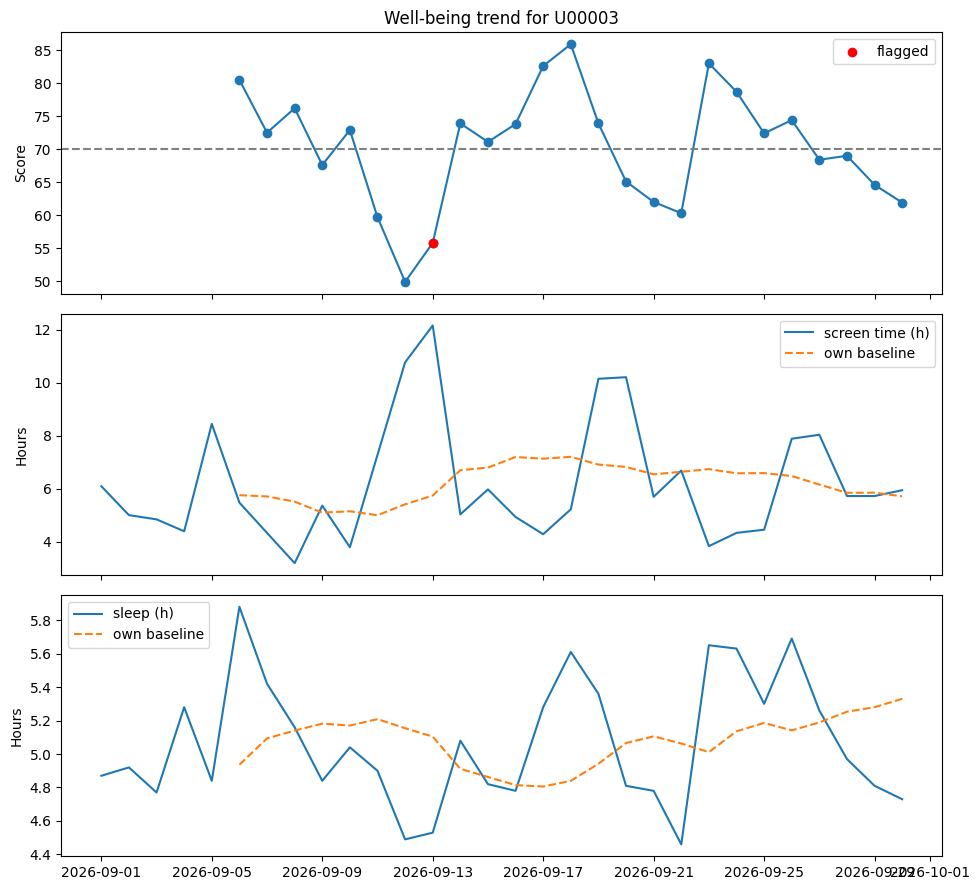

In [7]:
# pick a user with at least one flag, so the example shows a deviation
uid = df.loc[df.flagged == 1, "user_id"].iloc[0] if df.flagged.any() else df.user_id.iloc[0]
u = df[df.user_id == uid]

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax[0].plot(u.date, u.wellbeing_score, marker="o"); ax[0].axhline(70, ls="--", c="gray")
ax[0].scatter(u.date[u.flagged == 1], u.wellbeing_score[u.flagged == 1], c="red", zorder=3, label="flagged")
ax[0].set_ylabel("Score"); ax[0].legend(); ax[0].set_title(f"Well-being trend for {uid}")
ax[1].plot(u.date, u.daily_screen_time_hours, label="screen time (h)")
ax[1].plot(u.date, u.daily_screen_time_hours_base, ls="--", label="own baseline"); ax[1].legend(); ax[1].set_ylabel("Hours")
ax[2].plot(u.date, u.sleep_hours, label="sleep (h)")
ax[2].plot(u.date, u.sleep_hours_base, ls="--", label="own baseline"); ax[2].legend(); ax[2].set_ylabel("Hours")
plt.tight_layout(); plt.savefig(RESULTS / "example_user_trend.png", dpi=120); plt.show()

## 8. Which factors are linked to changes in well-being

Main driver on low-score days (%):


main_driver
Sleep                49.9
Screen time          47.0
Notifications         1.7
Physical activity     1.4
Name: proportion, dtype: float64

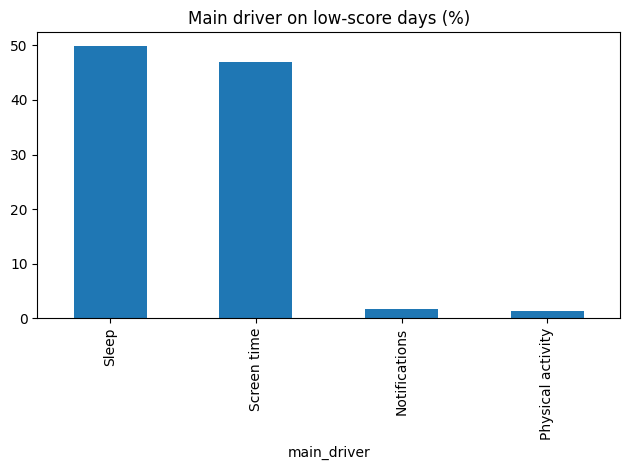

Average score contribution on flagged days (negative = pulls score down):


Screen time         -0.548
Sleep               -0.531
Physical activity   -0.099
Notifications       -0.193
dtype: float64

,normal days,flagged days
daily_screen_time_hours,8.01,11.49
sleep_hours,6.84,5.48
physical_activity_minutes,43.18,36.35
notifications_per_day,134.84,167.80


In [8]:
# (a) Which factor most often drives a low-score day?
low = df[df["has_baseline"] & (df["wellbeing_score"] < 60)]
drv = low["main_driver"].value_counts(normalize=True).mul(100).round(1)
print("Main driver on low-score days (%):"); display(drv)
drv.plot(kind="bar", title="Main driver on low-score days (%)"); plt.tight_layout()
plt.savefig(RESULTS / "main_driver.png", dpi=120); plt.show()

# (b) Average contribution of each factor on flagged days
fl = df[df.flagged == 1]
avg = fl[[c + "_contrib" for c in DIRECTION]].mean().rename(lambda s: LABEL[s.replace("_contrib", "")]).round(3)
print("Average score contribution on flagged days (negative = pulls score down):"); display(avg)

# (c) Do high-deviation days differ in raw habits? (compare flagged vs normal days)
cmp_ = df[df.has_baseline].groupby("flagged")[list(DIRECTION)].mean().round(2).T
cmp_.columns = ["normal days", "flagged days"]; display(cmp_)

**Caution for the report:** the score is built from these factors, so a factor driving a low score is partly by design. The correlation heatmap in Section 2 is the independent evidence of how habits relate to each other.

## 9. Save outputs for the Streamlit dashboard

In [9]:
keep = ["record_id", "user_id", "date", "day_index", "is_weekend"] + list(DIRECTION) + \
       [c + "_base" for c in DIRECTION] + \
       ["deviation", "wellbeing_score", "flagged", "anomaly", "main_driver", "recommendation"]
out = df[keep].copy()
out[[c for c in out.columns if c.endswith("_base")]] = out[[c for c in out.columns if c.endswith("_base")]].round(2)
out["deviation"] = out["deviation"].round(3)
out.to_csv(RESULTS / "wellbeing_scores_daily.csv", index=False)

# Same name and columns as the old placeholder file, now with the real score (plus new columns at the end)
orig = ["record_id", "user_id", "date", "day_index", "day_of_week", "is_weekend", "daily_screen_time_hours",
        "social_media_hours", "gaming_hours", "work_study_hours", "sleep_hours", "notifications_per_day",
        "app_opens_per_day", "physical_activity_minutes", "wellbeing_score"]
extra = ["deviation", "flagged", "anomaly", "main_driver", "recommendation"]
scored = df[orig + extra].copy()
scored["date"] = scored["date"].dt.strftime("%Y-%m-%d")
scored["deviation"] = scored["deviation"].round(3)
scored.to_csv(RESULTS / "digital_wellbeing_scored.csv", index=False)

df[df.flagged == 1][["user_id", "date", "wellbeing_score", "main_driver", "recommendation"]] \
  .to_csv(RESULTS / "flagged_deviations.csv", index=False)

summary = (df[df.has_baseline].groupby("user_id")
           .agg(avg_score=("wellbeing_score", "mean"), min_score=("wellbeing_score", "min"),
                flagged_days=("flagged", "sum"), anomaly_days=("anomaly", "sum"))
           .round(1).reset_index())
summary.to_csv(RESULTS / "user_summary.csv", index=False)

for f in ["digital_wellbeing_scored.csv", "wellbeing_scores_daily.csv", "flagged_deviations.csv", "user_summary.csv"]:
    print(f, "->", (RESULTS / f).stat().st_size // 1024, "KB")

digital_wellbeing_scored.csv -> 41909 KB
wellbeing_scores_daily.csv -> 39592 KB
flagged_deviations.csv -> 269 KB
user_summary.csv -> 178 KB


## 10. Summary for the report
- **Baseline:** each user is compared with their own previous 7 days, as the abstract requires.
- **Score:** 70 means typical for that user. Built from sleep, screen time, activity and notifications (stress and mood are not in the dataset).
- **Deviation detection:** a sustained-deviation rule plus an Isolation Forest model.
- **Explainability:** every day has a main driver and a message with the actual numbers.
- **Outputs** in `results/`: `wellbeing_scores_daily.csv`, `flagged_deviations.csv`, `user_summary.csv` and the charts.
- **Limits:** synthetic data, 30 days per user, weights chosen by the team, and batch processing (real-time is future scope).